# 3. Support Vector Machine / Destek Vektör Makinesi

**English theory:** [Classification](../Classification.md) · **Türkçe teori:** [Sınıflandırma](../Classification.tr.md) · [Notebook index / dizin](../README.md)

Compare linear and RBF kernels with training-only cross-validation. Draw a two-feature linear margin separately from the full 30-feature classifier.

**Türkçe:** Tam modelin ölçümünü, iki boyutlu marj çiziminin öğretici rolünden ayırıyoruz.

Run **Restart Kernel → Run All** to reproduce every output. Each notebook starts from raw local data and has no dependency on another notebook's variables. Saved tables and figures are actual executed outputs.

**Türkçe:** Sonuçları yeniden üretmek için çekirdeği yeniden başlatıp bütün hücreleri sırayla çalıştırın. Veri dosyaları repoda bulunur; başka bir notebook'un önceden çalıştırılması gerekmez.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, JSON

# Works when launched from this folder, Classification/, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
CLASSIFICATION_DIR = next(
    folder for base in candidates for folder in (base, base / "Classification")
    if (folder / "Classification.md").is_file()
    and (folder / "datasets" / "data.csv").is_file()
)
SEED = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 12)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "SciPy": scipy.__version__,
            "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="Environment"))

Python          3.10.11
NumPy            1.26.4
pandas            2.3.3
SciPy            1.13.1
scikit-learn      1.7.2
Matplotlib       3.10.9
Name: Environment, dtype: object

## Data and evaluation protocol / Veri ve ölçüm düzeni

The target is `B → 0`, `M → 1`. All six tabular classifiers use the **same stratified 80/20 split** (`random_state=42`), so their training CV scores can be compared. The final 114 rows are held out. Hyperparameters are chosen with five-fold CV **inside the 455 training rows**. A scaler belongs in a pipeline so each fold learns its own training minimum and maximum. Trees and GaussianNB do not need scaling.

**Türkçe:** Önce eğitim/test ayrımı yapılır. Ölçekleme ve model seçimi yalnız eğitim verisinden öğrenilir. Test verisi K, C veya derinlik seçmek için kullanılmaz. Eski notlardaki farklı ayrımla üretilmiş örnek yüzdeler bu çalıştırmayla birebir aynı olmak zorunda değildir.

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold

frame = pd.read_csv(CLASSIFICATION_DIR / "datasets" / "data.csv")
X = frame.drop(columns=["id", "diagnosis", "Unnamed: 32"])
y = frame["diagnosis"].map({"B": 0, "M": 1})
assert X.shape == (569, 30) and y.notna().all() and X.notna().all().all()
assert not X.columns.isin(["id", "diagnosis"]).any()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_test.index)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
display(pd.DataFrame({"all": y.value_counts(), "train": y_train.value_counts(),
                      "test": y_test.value_counts()}).rename(index={0: "Benign (0)", 1: "Malignant (1)"}))
display(X_train.head(3))
print(f"Train: {X_train.shape}; held-out test: {X_test.shape}")

,all,train,test
diagnosis,,,
Benign (0),357,285,72
Malignant (1),212,170,42


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,...,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,16.02,23.24,102.70,797.8,0.08206,0.06669,...,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452
170,12.32,12.39,78.85,464.1,0.10280,0.06981,...,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771
407,12.85,21.37,82.63,514.5,0.07551,0.08316,...,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151


Train: (455, 30); held-out test: (114, 30)


## Soft margin and kernels / Yumuşak marj ve çekirdekler

For signed labels $t_i\in\{-1,+1\}$, a soft-margin SVM minimizes
$$\frac12\lVert w\rVert^2+C\sum_i\max(0,1-t_i(w^\top x_i+b)).$$
The two supporting hyperplanes have scores `-1` and `+1`; their separation is $2/\lVert w\rVert$ in the transformed feature coordinates. RBF uses $K(x,x')=\exp(-\gamma\lVert x-x'\rVert^2)$ and can form curved boundaries. Larger `C` penalizes training violations more; larger `gamma` makes each training example's influence more local.

**Türkçe:** Marj çizgileri `f(x)=±1` düzeyleridir. RBF modeli doğrusal bir `w` vektörü sunmaz; çizimde bu nedenle ayrı bir doğrusal model kullanılır. C ve gamma test kümesine bakılmadan seçilir.

In [3]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([("scale", MinMaxScaler()), ("svm", SVC(random_state=SEED))])
grid = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10], "svm__gamma": ["scale", 0.1, 1]},
]
search = GridSearchCV(pipeline, grid, cv=cv, scoring="accuracy", n_jobs=1, error_score="raise")
search.fit(X_train, y_train)
model = search.best_estimator_
display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
        .sort_values("mean_test_score", ascending=False).rename(columns={"mean_test_score": "CV_accuracy"}))
print("Selected parameters:", search.best_params_)
print("Support vectors per class:", model.named_steps["svm"].n_support_)

,params,CV_accuracy,std_test_score
11,"{'svm__C': 10, 'svm__gamma': 1, 'svm__kernel':...",0.982418,0.008791
9,"{'svm__C': 10, 'svm__gamma': 'scale', 'svm__ke...",0.980220,0.008223
6,"{'svm__C': 1, 'svm__gamma': 'scale', 'svm__ker...",0.975824,0.008223
8,"{'svm__C': 1, 'svm__gamma': 1, 'svm__kernel': ...",0.975824,0.008223
1,"{'svm__C': 1, 'svm__kernel': 'linear'}",0.973626,0.011207
10,"{'svm__C': 10, 'svm__gamma': 0.1, 'svm__kernel...",0.971429,0.008791
2,"{'svm__C': 10, 'svm__kernel': 'linear'}",0.969231,0.012815
7,"{'svm__C': 1, 'svm__gamma': 0.1, 'svm__kernel'...",0.958242,0.012815
0,"{'svm__C': 0.1, 'svm__kernel': 'linear'}",0.951648,0.023671
3,"{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__k...",0.945055,0.030295


Selected parameters: {'svm__C': 10, 'svm__gamma': 1, 'svm__kernel': 'rbf'}
Support vectors per class: [34 33]


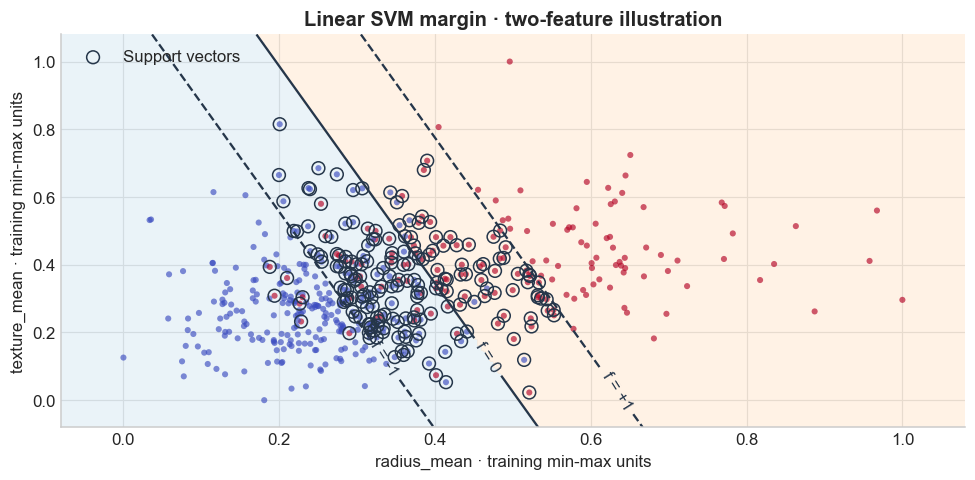

Margin width in scaled units: 0.2560


In [4]:
two_features = ["radius_mean", "texture_mean"]
illustration = make_pipeline(MinMaxScaler(), SVC(kernel="linear", C=1, random_state=SEED))
illustration.fit(X_train[two_features], y_train)
scale_2d, svm_2d = illustration.steps[0][1], illustration.steps[1][1]
train_2d = scale_2d.transform(X_train[two_features])
xx, yy = np.meshgrid(np.linspace(-.08, 1.08, 230), np.linspace(-.08, 1.08, 230))
grid_2d = np.c_[xx.ravel(), yy.ravel()]
scores = svm_2d.decision_function(grid_2d).reshape(xx.shape)
plt.contourf(xx, yy, scores >= 0, levels=[-.5, .5, 1.5], colors=["#D9EAF4", "#FFE8D1"], alpha=.55)
plt.scatter(*train_2d.T, c=y_train, cmap="coolwarm", s=16, alpha=.65, edgecolors="none")
contours = plt.contour(xx, yy, scores, levels=[-1, 0, 1], colors="#25364A", linestyles=["--", "-", "--"])
plt.clabel(contours, inline=True, fmt={-1: "f = -1", 0: "f = 0", 1: "f = +1"})
plt.scatter(*svm_2d.support_vectors_.T, s=70, facecolors="none", edgecolors="#25364A", label="Support vectors")
plt.xlabel("radius_mean · training min-max units")
plt.ylabel("texture_mean · training min-max units")
plt.title("Linear SVM margin · two-feature illustration")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()
print(f"Margin width in scaled units: {2 / np.linalg.norm(svm_2d.coef_[0]):.4f}")

              precision    recall  f1-score   support

      Benign     0.9600    1.0000    0.9796        72
   Malignant     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



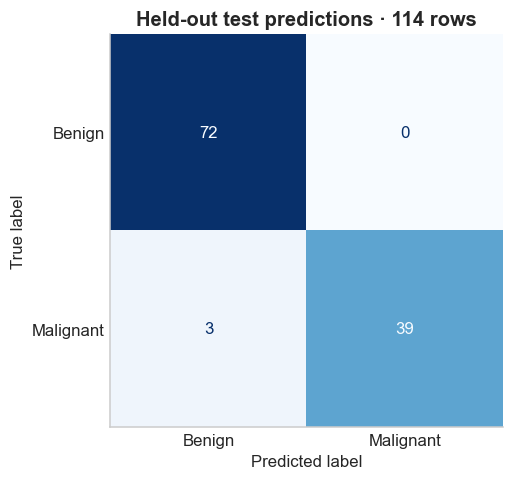

In [5]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

prediction = model.predict(X_test)
test_accuracy = accuracy_score(y_test, prediction)
test_macro_f1 = f1_score(y_test, prediction, average="macro")
print(classification_report(y_test, prediction, target_names=["Benign", "Malignant"], digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=["Benign", "Malignant"],
                                       cmap="Blues", colorbar=False)
plt.grid(False)
plt.title("Held-out test predictions · 114 rows")
plt.tight_layout()
plt.show()

## Measured result / Ölçülen sonuç

This summary is produced by the cells above; the runner also collects it in `Classification/notebook_results.json`. A single split is an educational experiment, not a guarantee for a different dataset.

**Türkçe:** Aşağıdaki değerler bu notebook'un gerçek çıktısıdır. Farklı veri veya ayrımlarda aynı sonuç garanti edilmez.

In [6]:
results = {"chapter": 3, "train_rows": len(X_train), "test_rows": len(X_test),
           "best_parameters": search.best_params_, "train_cv_accuracy": float(search.best_score_),
           "support_vectors": model.named_steps["svm"].n_support_.tolist(),
           "test_accuracy": float(test_accuracy), "test_macro_f1": float(test_macro_f1)}
results["versions"] = versions
display(JSON(results, expanded=True))

<IPython.core.display.JSON object>